In [ ]:
import base64
import subprocess
from pathlib import Path
from kaggle_secrets import UserSecretsClient

secrets = UserSecretsClient()
token = secrets.get_secret("GITHUB_TOKEN")

username = "AnikMallick"
repo_name = "bn-proverbs-in-context"

repo_dir = Path("/kaggle/working") / repo_name

auth = base64.b64encode(
    f"{username}:{token}".encode()
).decode()

try:
    subprocess.run(
        [
            "git",
            "-c",
            f"http.https://github.com/.extraheader="
            f"AUTHORIZATION: basic {auth}",
            "clone",
            f"https://github.com/{username}/{repo_name}.git",
            str(repo_dir),
        ],
        check=True,
    )
finally:
    del token
    del auth

print("Repository cloned successfully.")

In [ ]:
%cd /kaggle/working/bn-proverbs-in-context

!pip install -e .

In [1]:
from pathlib import Path
from probad.utils import print_div
from probad.schema import TestItem, validate_items
import json
from typing import Any
import probad.builder as exp

DATA_PATH = Path("/kaggle/input/datasets/amallick0507/probad")

train_data = list(TestItem.load_items(DATA_PATH/"train.jsonl"))
test_data = list(TestItem.load_items(DATA_PATH/"test.jsonl"))
val_data = list(TestItem.load_items(DATA_PATH/"val.jsonl"))


source = DATA_PATH / "stopwords-bn.json"

try:
    data: Any = json.loads(source.read_text(encoding="utf-8-sig"))
except FileNotFoundError as exc:
    raise FileNotFoundError(f"Stopword file not found: {source}") from exc
except json.JSONDecodeError as exc:
    raise ValueError(
        f"Invalid JSON in stopword file {source}: "
        f"line {exc.lineno}, column {exc.colno}: {exc.msg}"
    ) from exc

BN_STOPWORDS =  frozenset([word.strip() for word in data])

print_div("train")
for issue in validate_items(train_data, BN_STOPWORDS):
    print(issue)

print_div("test")
for issue in validate_items(test_data, BN_STOPWORDS):
    print(issue)

print_div("val")
for issue in validate_items(val_data, BN_STOPWORDS):
    print(issue)

=============================================> train <==============================================
==============================================> test <==============================================
[WARNING] prv_088_1: en.correct_echoes_gloss: correct option reuses many literal-gloss words
[WARNING] prv_088_2: en.correct_echoes_gloss: correct option reuses many literal-gloss words
==============================================> val <===============================================


In [ ]:
# from kaggle_secrets import UserSecretsClient
# import os
# from probad.scoring import LoadBalancedModel

# user_secrets = UserSecretsClient()
# secret_value_1 = user_secrets.get_secret("HF_TOKEN")
# os.environ['HF_TOKEN'] = secret_value_1

# MODEL_NAME = "allenai/OLMo-2-0425-1B"
# model = LoadBalancedModel(
#     MODEL_NAME,
#     gpu_ids=(0, 1)
# )

# tok = model.tok

In [2]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from kaggle_secrets import UserSecretsClient
import os
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForImageTextToText,
    BitsAndBytesConfig
)
# from probad.scoring import LoadBalancedModel

user_secrets = UserSecretsClient()
secret_value_1 = user_secrets.get_secret("HF_TOKEN")
os.environ['HF_TOKEN'] = secret_value_1

MODEL_ID = "bigscience/bloomz-7b1-mt"

# tokenizer = AutoTokenizer.from_pretrained(checkpoint)
# model = AutoModelForCausalLM.from_pretrained(checkpoint, torch_dtype="auto", device_map="auto")

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.float16
)

model.eval()

inputs = tokenizer.encode("Translate to English: Je t’aime.", return_tensors="pt").to("cuda")
outputs = model.generate(inputs)
print(tokenizer.decode(outputs[0]))


config.json:   0%|          | 0.00/747 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/199 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 14.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.1GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/365 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1963: UserWarning: Using the model-agnostic default `max_length` (=27) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Translate to English: Je t’aime. I love you.</s>


In [3]:
import pandas as pd


## X1
correct_vs_literal 

In [4]:
MODEL_NAME = MODEL_ID
tok = tokenizer

In [6]:
from probad.scoring import answer_one, generate, check_memorisation, check_memorisation_graded
from probad.builder import MEM_TEMPLATES
from itertools import product
from concurrent.futures import ThreadPoolExecutor, as_completed

In [8]:
def item_info(it):
    return {"item_id": it["item_id"], "proverb_id": it["proverb"]["proverb_id"],
            "figurative": it["proverb"]["figurative"], "split": it["meta"]["split"],
            "subsets": it["meta"].get("subsets", [])}

In [9]:
def process_item(item, lang):
    r = exp.x1_correct_vs_literal(item.model_dump(), lang=lang)

    return {
        "model": MODEL_NAME,
        "label": "x1_correct_vs_literal",
        "variant": f"exp.x1_correct_vs_literal(item.model_dump(), {lang})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["en", "bn"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [11]:
x1_results_df = pd.DataFrame(results)
display(x1_results_df.head(2))
sum(x1_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x1_correct_vs_literal,"exp.x1_correct_vs_literal(item.model_dump(), en)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.846958,0.153042,1.710938,0.000025
1,bigscience/bloomz-7b1-mt,x1_correct_vs_literal,"exp.x1_correct_vs_literal(item.model_dump(), bn)",prv_001_1,prv_001,True,test,[maps_overlap],a,b,False,0.014778,0.985222,-4.199706,0.000001


951

In [50]:
def udf(x):
    match = re.search(r"x1_correct_vs_literal\(item\.model_dump\(\),\s*(\w+)\)", x)

    return f"x1_{match.group(1)}" if match else None
import re
x1_results_df["label"] = x1_results_df["variant"].apply(udf)
x1_results_df.head(1)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x1_en,"exp.x1_correct_vs_literal(item.model_dump(), en)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.846958,0.153042,1.710938,0.000025


## X2
negative

In [12]:
def process_item(item, lang):
    r = exp.x2_negative(item.model_dump(), lang=lang)

    return {
        "model": MODEL_NAME,
        "label": "x2_negative",
        "variant": f"exp.x2_negative(item.model_dump(), {lang})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["en", "bn"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [13]:
x2_results_df = pd.DataFrame(results)
display(x2_results_df.head(2))
sum(x2_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x2_negative,"exp.x2_negative(item.model_dump(), en)",prv_001_1,prv_001,True,test,[maps_overlap],b,b,True,0.214691,0.785309,1.296875,6.006287e-06
1,bigscience/bloomz-7b1-mt,x2_negative,"exp.x2_negative(item.model_dump(), bn)",prv_001_1,prv_001,True,test,[maps_overlap],b,b,True,0.016301,0.983699,4.100099,9.081406e-07


535

In [52]:
def udf(x):
    match = re.search(r"x2_negative\(item\.model_dump\(\),\s*(\w+)\)", x)

    return f"x2_{match.group(1)}" if match else None
import re
x2_results_df["label"] = x2_results_df["variant"].apply(udf)
x2_results_df.head(1)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x2_en,"exp.x2_negative(item.model_dump(), en)",prv_001_1,prv_001,True,test,[maps_overlap],b,b,True,0.214691,0.785309,1.296875,0.000006


## X3
with none

In [14]:
def process_item(item, lang):
    r = exp.x3_none_of_these(item.model_dump(), lang=lang)

    return {
        "model": MODEL_NAME,
        "label": "x3_none_of_these",
        "variant": f"exp.x3_none_of_these(item.model_dump(), {lang})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["en", "bn"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [15]:
x3_results_df = pd.DataFrame(results)
display(x3_results_df.head(2))
sum(x3_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,p_c,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x3_none_of_these,"exp.x3_none_of_these(item.model_dump(), bn)",prv_001_1,prv_001,True,test,[maps_overlap],c,b,False,0.037536,0.92734,0.035124,-3.273437,0.000002
1,bigscience/bloomz-7b1-mt,x3_none_of_these,"exp.x3_none_of_these(item.model_dump(), en)",prv_001_1,prv_001,True,test,[maps_overlap],c,b,False,0.091533,0.86506,0.043407,-2.992188,0.000003


369

In [58]:
def udf(x):
    match = re.search(r"x3_none_of_these\(item\.model_dump\(\),\s*(\w+)\)", x)

    return f"x3_{match.group(1)}" if match else None
import re
x3_results_df["label"] = x3_results_df["variant"].apply(udf)
x3_results_df.head(1)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,p_c,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x3_bn,"exp.x3_none_of_these(item.model_dump(), bn)",prv_001_1,prv_001,True,test,[maps_overlap],c,b,False,0.037536,0.92734,0.035124,-3.273437,0.000002


## X4
meaning_no_context

In [16]:
def process_item(item, lang):
    r = exp.x4_meaning_no_context(item.model_dump(), lang=lang)

    return {
        "model": MODEL_NAME,
        "label": "x4_meaning_no_context",
        "variant": f"exp.x4_meaning_no_context(item.model_dump(), {lang})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["en", "bn"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [17]:
x4_results_df = pd.DataFrame(results)
display(x4_results_df.head(2))
sum(x4_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x4_meaning_no_context,"exp.x4_meaning_no_context(item.model_dump(), bn)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.729520,0.270480,0.992188,6.343923e-07
1,bigscience/bloomz-7b1-mt,x4_meaning_no_context,"exp.x4_meaning_no_context(item.model_dump(), en)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.970799,0.029201,3.503906,2.194649e-05


847

In [59]:
def udf(x):
    match = re.search(r"x4_meaning_no_context\(item\.model_dump\(\),\s*(\w+)\)", x)

    return f"x4_{match.group(1)}" if match else None
import re
x4_results_df["label"] = x4_results_df["variant"].apply(udf)
x4_results_df.head(1)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x4_bn,"exp.x4_meaning_no_context(item.model_dump(), bn)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.72952,0.27048,0.992188,6.343923e-07


## X5
three_way

In [18]:
def process_item(item, lang):
    r = exp.x5_three_way(item.model_dump(), lang=lang)

    return {
        "model": MODEL_NAME,
        "label": "x5_three_way",
        "variant": f"exp.x5_three_way(item.model_dump(), {lang})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["en", "bn"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [19]:
x5_results_df = pd.DataFrame(results)
display(x5_results_df.head(2))
sum(x5_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,p_c,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x5_three_way,"exp.x5_three_way(item.model_dump(), en)",prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.624260,0.285807,0.089933,-0.781250,0.000030
1,bigscience/bloomz-7b1-mt,x5_three_way,"exp.x5_three_way(item.model_dump(), bn)",prv_001_1,prv_001,True,test,[maps_overlap],b,c,False,0.004187,0.370491,0.625322,-0.523438,0.000005


850

In [60]:
def udf(x):
    match = re.search(r"x5_three_way\(item\.model_dump\(\),\s*(\w+)\)", x)

    return f"x5_{match.group(1)}" if match else None
import re
x5_results_df["label"] = x5_results_df["variant"].apply(udf)
x5_results_df.head(1)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,p_c,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x5_en,"exp.x5_three_way(item.model_dump(), en)",prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.62426,0.285807,0.089933,-0.78125,0.00003


## X6
render

In [20]:
def process_item(item, render):
    # r = exp.x6_render(train_data[0].model_dump(),render="romanised")

    r = exp.x6_render(item.model_dump(), render=render)

    return {
        "model": MODEL_NAME,
        "label": "x6_render",
        "variant": f"exp.x6_render(item.model_dump(), {render})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["romanised", "gloss", "gloss_only", "bengali"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [21]:
x6_results_df = pd.DataFrame(results)
display(x6_results_df.head(2))
sum(x6_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x6_render,"exp.x6_render(item.model_dump(), gloss)",prv_001_1,prv_001,True,test,[maps_overlap],a,b,False,0.498047,0.501953,-0.007812,0.000012
1,bigscience/bloomz-7b1-mt,x6_render,"exp.x6_render(item.model_dump(), romanised)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.846958,0.153042,1.710938,0.000025


2084

In [61]:
def udf(x):
    match = re.search(r"x6_render\(item\.model_dump\(\),\s*(\w+)\)", x)

    return f"x6_{match.group(1)}" if match else None
import re
x6_results_df["label"] = x6_results_df["variant"].apply(udf)
x6_results_df.head(1)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x6_gloss,"exp.x6_render(item.model_dump(), gloss)",prv_001_1,prv_001,True,test,[maps_overlap],a,b,False,0.498047,0.501953,-0.007812,0.000012


## X7
no_question

In [22]:
def process_item(item, lang):
    r = exp.x7_no_question(item.model_dump(), lang=lang)

    return {
        "model": MODEL_NAME,
        "label": "x7_no_question",
        "variant": f"exp.x7_no_question(item.model_dump(), {lang})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["en", "bn"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [23]:
x7_results_df = pd.DataFrame(results)
display(x7_results_df.head(2))
sum(x7_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x7_no_question,"exp.x7_no_question(item.model_dump(), bn)",prv_001_1,prv_001,True,test,[maps_overlap],a,b,False,0.026708,0.973292,-3.595703,0.000003
1,bigscience/bloomz-7b1-mt,x7_no_question,"exp.x7_no_question(item.model_dump(), en)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.930962,0.069038,2.601562,0.000027


1007

In [62]:
def udf(x):
    match = re.search(r"x7_no_question\(item\.model_dump\(\),\s*(\w+)\)", x)

    return f"x7_{match.group(1)}" if match else None
import re
x7_results_df["label"] = x7_results_df["variant"].apply(udf)
x7_results_df.head(1)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x7_bn,"exp.x7_no_question(item.model_dump(), bn)",prv_001_1,prv_001,True,test,[maps_overlap],a,b,False,0.026708,0.973292,-3.595703,0.000003


## X8
with prompt

In [28]:
exp.x7_no_question(train_data[0].model_dump(), lang="bn")

('রাজেশ: সুমন সপ্তাহের পর সপ্তাহ অনলাইনে প্রাক্তন সহকর্মীকে ট্রোল করেছিল, আর এখন সে সুমনের পুরোনো লজ্জার সব মেসেজ পোস্ট করে দিয়েছে।\nইপ্সিতা: ইটটি মারলে পাটকেলটি খেতে হয়।\n\nA. কাউকে লক্ষ্য করে ইট ছুড়লে উল্টো দিক থেকে একটা ঢিল এসে নিজের গায়েই লাগে।\nB. সুমন আগে আঘাত করেছিল, তাই পাল্টা আঘাত আসাটাই স্বাভাবিক ছিল।\nউত্তর:',
 'b',
 ['a', 'b'])

In [29]:
exp.x8_system_prompt(train_data[0].model_dump(), condition="C1b")

('You are a native Bengali speaker who grew up in a middle-class family in Kolkata and has family in rural Bengal and Bangladesh. You speak Bengali at home and English at college and work, and you often switch between the two. You know Bengali proverbs (probad) from your grandparents, from school and from everyday conversation, and you know that people use them to comment on a situation, tease, warn or give advice rather than to talk about the literal objects in them. The people in the conversations you read are Bengali friends, family members, classmates and colleagues talking about ordinary life.',
 'Rajesh: Sumon trolled his ex-colleague online for weeks, and now she has posted all his old embarrassing messages.\nIpsita: Itti marle patkelti khete hoy.\n\nQuestion: What does Ipsita mean?\nA. Throw a brick at someone and a stone comes back at you.\nB. Sumon hurt her first, so he should have expected to be hurt back.\nAnswer:',
 'b',
 ['a', 'b'])

In [31]:
def process_item(item, condition):
    # r = exp.x8_system_prompt(train_data[0].model_dump(), condition="C0")


    r = exp.x8_system_prompt(item.model_dump(), condition=condition)

    return {
        "model": MODEL_NAME,
        "label": "x8_system_prompt",
        "variant": f"exp.x8_system_prompt(item.model_dump(), {condition})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[1], r[2], r[3],
            system=r[0],
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["C0", "C1a", "C1b"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [32]:
x8_results_df = pd.DataFrame(results)
display(x8_results_df.head(2))
sum(x8_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x8_system_prompt,"exp.x8_system_prompt(item.model_dump(), C1a)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.909907,0.090093,2.312500,0.000036
1,bigscience/bloomz-7b1-mt,x8_system_prompt,"exp.x8_system_prompt(item.model_dump(), C0)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.846958,0.153042,1.710938,0.000025


1743

In [48]:
x8_results_df.shape

(1800, 15)

In [76]:
def udf(x):
    match = re.search(r"x8_system_prompt\(item\.model_dump\(\),\s*(\w+)\)", x)

    return f"x8_en_{match.group(1)}" if match else None
import re
x8_results_df["label"] = x8_results_df["variant"].apply(udf)
x8_results_df.head(1)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x8_en_C1a,"exp.x8_system_prompt(item.model_dump(), C1a)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.909907,0.090093,2.3125,0.000036


## X8 bn

In [82]:
exp.x8_system_prompt(train_data[0].model_dump(), lang="bn", condition="C1b")

('You are a native Bengali speaker who grew up in a middle-class family in Kolkata and has family in rural Bengal and Bangladesh. You speak Bengali at home and English at college and work, and you often switch between the two. You know Bengali proverbs (probad) from your grandparents, from school and from everyday conversation, and you know that people use them to comment on a situation, tease, warn or give advice rather than to talk about the literal objects in them. The people in the conversations you read are Bengali friends, family members, classmates and colleagues talking about ordinary life.',
 'রাজেশ: সুমন সপ্তাহের পর সপ্তাহ অনলাইনে প্রাক্তন সহকর্মীকে ট্রোল করেছিল, আর এখন সে সুমনের পুরোনো লজ্জার সব মেসেজ পোস্ট করে দিয়েছে।\nইপ্সিতা: ইটটি মারলে পাটকেলটি খেতে হয়।\n\nপ্রশ্ন: ইপ্সিতা কী বোঝাতে চাইছে?\nA. কাউকে লক্ষ্য করে ইট ছুড়লে উল্টো দিক থেকে একটা ঢিল এসে নিজের গায়েই লাগে।\nB. সুমন আগে আঘাত করেছিল, তাই পাল্টা আঘাত আসাটাই স্বাভাবিক ছিল।\nউত্তর:',
 'b',
 ['a', 'b'])

In [77]:
def process_item(item, condition):
    # r = exp.x8_system_prompt(train_data[0].model_dump(), condition="C0")


    r = exp.x8_system_prompt(item.model_dump(), lang="bn", condition=condition)

    return {
        "model": MODEL_NAME,
        "label": f"x8_bn_{condition}",
        "variant": f"exp.x8_system_prompt(item.model_dump(), bn, {condition})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[1], r[2], r[3],
            system=r[0],
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["C0", "C1a", "C1b"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [78]:
x8_bn_results_df = pd.DataFrame(results)
display(x8_bn_results_df.head(2))
sum(x8_bn_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x8_bn_C1a,"exp.x8_system_prompt(item.model_dump(), bn, C1a)",prv_001_1,prv_001,True,test,[maps_overlap],a,b,False,0.025541,0.974459,-3.641603,0.000002
1,bigscience/bloomz-7b1-mt,x8_bn_C0,"exp.x8_system_prompt(item.model_dump(), bn, C0)",prv_001_1,prv_001,True,test,[maps_overlap],a,b,False,0.014778,0.985222,-4.199706,0.000001


1192

## X8 but bengali prompt

In [92]:
SYSTEM_PROMPTS_BN = {
    "C0": None,
    "C1a": "তুমি বাংলায় বড় হওয়া একজন বাঙালি, বাংলা তোমার মাতৃভাষা।",
    "C1b": ("তুমি কলকাতার এক মধ্যবিত্ত পরিবারে বড় হওয়া একজন বাঙালি, বাংলা তোমার মাতৃভাষা। "
            "গ্রামবাংলায় আর বাংলাদেশেও তোমার আত্মীয়স্বজন আছেন। বাড়িতে তুমি বাংলায় কথা বলো, "
            "কলেজে আর কাজের জায়গায় ইংরেজিতে, আর প্রায়ই দুই ভাষা মিশিয়ে কথা বলো। "
            "দাদু-ঠাকুমার কাছে, স্কুলে আর রোজকার কথাবার্তায় শুনে শুনে তুমি অনেক বাংলা প্রবাদ জানো। "
            "তুমি জানো, মানুষ প্রবাদ বলে কোনো পরিস্থিতি নিয়ে মন্তব্য করতে, ঠাট্টা করতে, সাবধান করতে "
            "কিংবা উপদেশ দিতে; প্রবাদে যে জিনিসগুলোর কথা আছে, সেগুলোর আক্ষরিক অর্থে কিছু বলতে নয়। "
            "যে কথোপকথনগুলো তুমি পড়বে, তাতে বাঙালি বন্ধুবান্ধব, পরিবারের লোকজন, সহপাঠী আর সহকর্মীরা "
            "রোজকার জীবনের নানা বিষয়ে কথা বলছে।"),
}

In [96]:
def x8_bn_system_prompt(item, condition="C1b", lang="en", seed=0, system=None):
    """C0 / C1a / C1b persona prompts; pass system=<GEPA best prompt> for C1c.
    Returns (system, prompt, gold)."""
    prompt, gold, all_options = exp.x1_correct_vs_literal(item, lang, seed=seed)
    return (system if system is not None else SYSTEM_PROMPTS_BN[condition]), prompt, gold, all_options


In [97]:
def process_item(item, condition):
    # r = exp.x8_system_prompt(train_data[0].model_dump(), condition="C0")


    r = x8_bn_system_prompt(item.model_dump(), condition=condition)

    return {
        "model": MODEL_NAME,
        "label": f"x8_en_pbn_{condition}",
        "variant": f"x8_bn_system_prompt(item.model_dump(), {condition})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[1], r[2], r[3],
            system=r[0],
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["C0", "C1a", "C1b"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [98]:
x8_en_pbn_results_df = pd.DataFrame(results)
display(x8_en_pbn_results_df.head(2))
sum(x8_en_pbn_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x8_en_pbn_C1a,"x8_bn_system_prompt(item.model_dump(), C1a)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.842863,0.157137,1.679688,0.000033
1,bigscience/bloomz-7b1-mt,x8_en_pbn_C0,"x8_bn_system_prompt(item.model_dump(), C0)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.846958,0.153042,1.710938,0.000025


1749

In [99]:
def process_item(item, condition):
    # r = exp.x8_system_prompt(train_data[0].model_dump(), condition="C0")


    r = x8_bn_system_prompt(item.model_dump(), lang="bn",condition=condition)

    return {
        "model": MODEL_NAME,
        "label": f"x8_bn_pbn_{condition}",
        "variant": f"x8_bn_system_prompt(item.model_dump(), bn, {condition})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[1], r[2], r[3],
            system=r[0],
            chat=False
        )
    }


results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["C0", "C1a", "C1b"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [100]:
x8_bn_pbn_results_df = pd.DataFrame(results)
display(x8_bn_pbn_results_df.head(2))
sum(x8_bn_pbn_results_df["correct"])

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,bigscience/bloomz-7b1-mt,x8_bn_pbn_C1a,"x8_bn_system_prompt(item.model_dump(), bn, C1a)",prv_001_1,prv_001,True,test,[maps_overlap],a,b,False,0.026861,0.973139,-3.589845,0.000002
1,bigscience/bloomz-7b1-mt,x8_bn_pbn_C0,"x8_bn_system_prompt(item.model_dump(), bn, C0)",prv_001_1,prv_001,True,test,[maps_overlap],a,b,False,0.014778,0.985222,-4.199706,0.000001


1104

## Saving

In [34]:
OUT = Path("/kaggle/working/results_mine_alligned_bloomz")
os.mkdir(OUT)

In [102]:
x1_results_df.to_csv(OUT / "x1_results_df.csv", index=False)
x2_results_df.to_csv(OUT / "x2_results_df.csv", index=False)
x3_results_df.to_csv(OUT / "x3_results_df.csv", index=False)
x4_results_df.to_csv(OUT / "x4_results_df.csv", index=False)
x5_results_df.to_csv(OUT / "x5_results_df.csv", index=False)
x6_results_df.to_csv(OUT / "x6_results_df.csv", index=False)
x7_results_df.to_csv(OUT / "x7_results_df.csv", index=False)
x8_results_df.to_csv(OUT / "x8_results_df.csv", index=False)
x8_bn_results_df.to_csv(OUT / "x8_bn_results_df.csv", index=False)
x8_en_pbn_results_df.to_csv(OUT / "x8_en_pbn_results_df.csv", index=False)
x8_bn_pbn_results_df.to_csv(OUT / "x8_bn_pbn_results_df.csv", index=False)

## Analysis

In [103]:
import random
import numpy as np, pandas as pd, matplotlib.pyplot as plt

FIG = OUT / "figs_x"; FIG.mkdir(parents=True, exist_ok=True)

RUNS = {"x1": x1_results_df, "x2": x2_results_df, "x3": x3_results_df, "x4": x4_results_df,
        "x5": x5_results_df, "x6": x6_results_df, "x7": x7_results_df, "x8": x8_results_df, "x8_bn": x8_bn_results_df,
       "x8_en_pbn": x8_en_pbn_results_df, "x8_bn_pdb": x8_bn_pbn_results_df}
NEG_PAIRS     = [("x1_en", "x2_en"), ("x1_bn", "x2_bn")]   # (what does X mean?, what does X NOT mean?)
KNOW_PAIRS    = [("x4_en", "x1_en"), ("x4_bn", "x1_bn")]   # (meaning without context, meaning in context)
CONTROL_PAIRS = [("x1_en", "x7_en"), ("x1_bn", "x7_bn")]   # (with question, no question)
X6_REF, X8_REF = "x6_romanised", "x8_C0"                    # baselines for the render / persona plots

ALL = pd.concat([df.assign(exp=name) for name, df in RUNS.items()], ignore_index=True)
ALL["gold"], ALL["pred"] = ALL["gold"].str.lower(), ALL["pred"].str.lower()
print("labels:", sorted(ALL["label"].unique()))
sub = lambda label: ALL[ALL["label"] == label]
have = lambda *labels: all((ALL["label"] == l).any() for l in labels) or print("skip, label missing:", labels)

labels: ['x1_bn', 'x1_en', 'x2_bn', 'x2_en', 'x3_bn', 'x3_en', 'x4_bn', 'x4_en', 'x5_bn', 'x5_en', 'x6_bengali', 'x6_gloss', 'x6_gloss_only', 'x6_romanised', 'x7_bn', 'x7_en', 'x8_bn_C0', 'x8_bn_C1a', 'x8_bn_C1b', 'x8_bn_pbn_C0', 'x8_bn_pbn_C1a', 'x8_bn_pbn_C1b', 'x8_en_C0', 'x8_en_C1a', 'x8_en_C1b', 'x8_en_pbn_C0', 'x8_en_pbn_C1a', 'x8_en_pbn_C1b']


In [37]:
def item_level(df, by=("label",)):
    """Collapse option orders: one row per item. correct = share of orders right;
    correct_db = mean P(gold) > 0.5 (2 options, cancels position bias when both orders were scored)."""
    df = df.copy()
    df["p_gold"] = df.apply(lambda r: r[f"p_{r['gold']}"], axis=1)
    df["n_opts"] = df.filter(regex=r"^p_[abc]$").notna().sum(axis=1)
    keys = [k for k in dict.fromkeys([*by, "item_id", "proverb_id", "figurative"]) if k in df]
    it = df.groupby(keys, dropna=False).agg(
        correct=("correct", "mean"), p_gold=("p_gold", "mean"), margin=("margin", "mean"),
        letter_mass=("letter_mass", "mean"), n_opts=("n_opts", "first"),
        n_orders=("correct", "size")).reset_index()
    it["correct_db"] = np.where((it["n_opts"] == 2) & (it["n_orders"] >= 2), it["p_gold"] > 0.5, np.nan)
    return it

def ci(values, clusters, n=2000, seed=0):
    """95% CI of the mean, resampling whole proverbs."""
    _, inv = np.unique(np.asarray(clusters), return_inverse=True)
    s, c = np.bincount(inv, np.asarray(values, float)), np.bincount(inv)
    pick = np.random.default_rng(seed).integers(0, len(c), (n, len(c)))
    return np.percentile(s[pick].sum(1) / c[pick].sum(1), [2.5, 97.5])

def summary(df, by="label"):
    it = item_level(df, (by,))
    rows = []
    for key, g in it.groupby(by):
        lo, hi = ci(g["correct"], g["proverb_id"])
        raw = df[df[by] == key]
        rows.append({by: key, "acc": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi,
                     "chance": 1 / g["n_opts"].mean(), "acc_db": g["correct_db"].mean(), "n": len(g),
                     "p_gold": g["p_gold"].mean(), "letter_mass": g["letter_mass"].median(),
                     "pred_a": (raw["pred"] == "a").mean(), "pred_b": (raw["pred"] == "b").mean(),
                     "pred_c": (raw["pred"] == "c").mean()})
    return pd.DataFrame(rows)

def paired(a, b, name_a, name_b):
    """b - a on shared items, CI over proverbs."""
    m = item_level(a, ()).merge(item_level(b, ()), on=["item_id", "proverb_id"], suffixes=("_a", "_b"))
    d = m["correct_b"] - m["correct_a"]
    lo, hi = ci(d, m["proverb_id"])
    return {"a": name_a, "b": name_b, "acc_a": m["correct_a"].mean(), "acc_b": m["correct_b"].mean(),
            "diff": d.mean(), "ci_lo": lo, "ci_hi": hi, "a_only": int((d < 0).sum()),
            "b_only": int((d > 0).sum()), "n": len(m)}

def bar(tab, title, fname, x="label"):
    fig, ax = plt.subplots(figsize=(max(4, 0.9 * len(tab) + 2), 3.5))
    ax.bar(tab[x].astype(str), tab["acc"], yerr=[tab["acc"] - tab["ci_lo"], tab["ci_hi"] - tab["acc"]],
           capsize=4, color="#4C72B0")
    for i, c in enumerate(tab["chance"]):
        ax.hlines(c, i - 0.4, i + 0.4, colors="red", linestyles="--")
    ax.set_ylim(0, 1); ax.set_ylabel("accuracy"); ax.set_title(title)
    plt.xticks(rotation=30, ha="right"); plt.tight_layout(); fig.savefig(FIG / fname, dpi=150); plt.show()

def forest(tab, title, fname):
    fig, ax = plt.subplots(figsize=(6, 0.4 * len(tab) + 1.5))
    ax.errorbar(tab["diff"], range(len(tab)), xerr=[tab["diff"] - tab["ci_lo"], tab["ci_hi"] - tab["diff"]], fmt="o")
    ax.axvline(0, color="grey", ls="--"); ax.set_yticks(range(len(tab)), tab["b"].astype(str))
    ax.set_xlabel(f"accuracy − {tab['a'].iloc[0]} (95% CI)"); ax.set_title(title)
    plt.tight_layout(); fig.savefig(FIG / fname, dpi=150); plt.show()

def heat(ax, tab, title):
    ax.imshow(tab.values, cmap="Blues")
    for (r, c), v in np.ndenumerate(tab.values):
        ax.text(c, r, v, ha="center", va="center")
    ax.set_xticks(range(tab.shape[1]), tab.columns); ax.set_yticks(range(tab.shape[0]), tab.index); ax.set_title(title)

def picked_key(df, keys, none_last=False):
    """Which option (correct / literal / plausible / none) each answer letter was. Re-creates the
    shuffle in own_mcq; assumes seed 0 unless df has a 'seed' column."""
    def keys_for(item_id, seed):
        k = list(keys)
        rng = random.Random(f"{item_id}|{seed}")
        if none_last:
            rest = [x for x in k if x != "none"]; rng.shuffle(rest); k = rest + ["none"]
        else:
            rng.shuffle(k)
        return dict(zip("abc", k))
    seeds = df["seed"] if "seed" in df else pd.Series(0, index=df.index)
    maps_ = [keys_for(i, s) for i, s in zip(df["item_id"], seeds)]
    return df.assign(pred_key=[m[p] for m, p in zip(maps_, df["pred"])],
                     gold_key=[m[g] for m, g in zip(maps_, df["gold"])])


            label    acc  ci_lo  ci_hi  chance  acc_db    n  p_gold  letter_mass  pred_a  pred_b  pred_c
0           x1_bn  0.617  0.577  0.657   0.500     NaN  600   0.629          0.0   0.107   0.893   0.000
1           x1_en  0.968  0.952  0.982   0.500     NaN  600   0.882          0.0   0.498   0.502   0.000
2           x2_bn  0.408  0.367  0.452   0.500     NaN  600   0.387          0.0   0.082   0.918   0.000
3           x2_en  0.483  0.442  0.520   0.500     NaN  600   0.485          0.0   0.163   0.837   0.000
4           x3_bn  0.567  0.513  0.620   0.333     NaN  600   0.511          0.0   0.055   0.378   0.567
5           x3_en  0.048  0.030  0.070   0.333     NaN  600   0.154          0.0   0.587   0.365   0.048
6           x4_bn  0.527  0.482  0.573   0.500     NaN  600   0.528          0.0   0.120   0.880   0.000
7           x4_en  0.885  0.850  0.917   0.500     NaN  600   0.782          0.0   0.542   0.458   0.000
8           x5_bn  0.577  0.533  0.622   0.333     NaN 

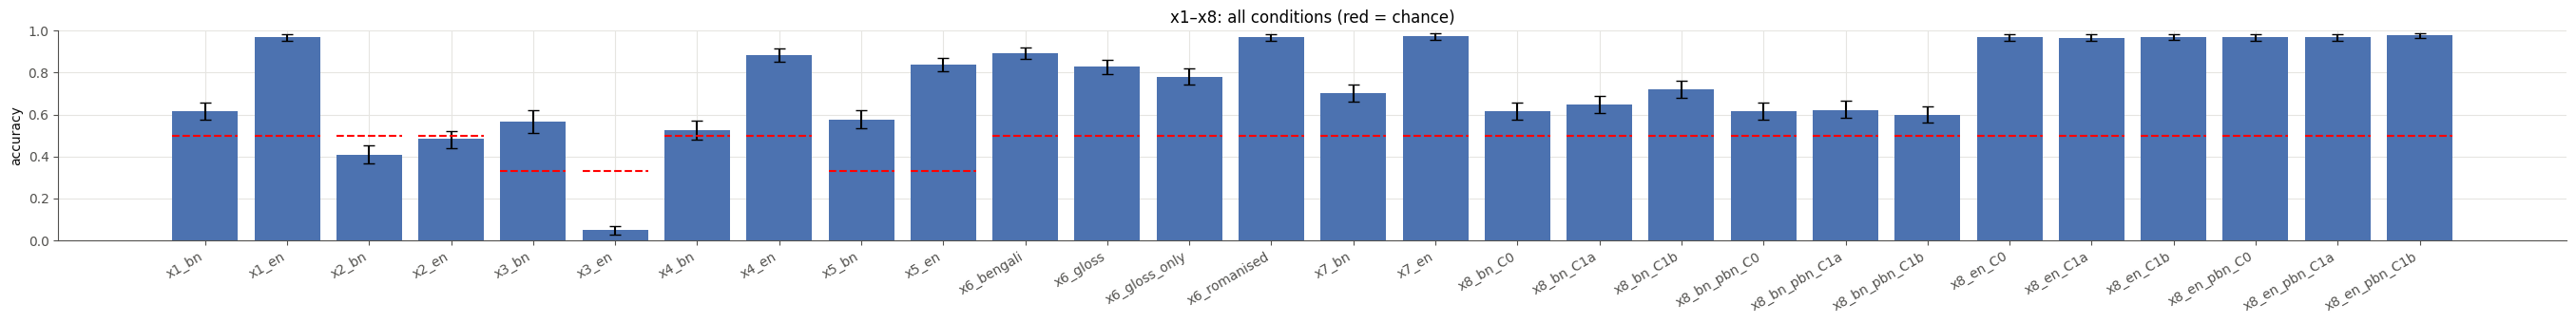

In [104]:
overview = summary(ALL)
overview.to_csv(OUT / "x_overview.csv", index=False)
print(overview.round(3).to_string())
bar(overview, "x1–x8: all conditions (red = chance)", "x_overview.png")

   figurative    acc  ci_lo  ci_hi  chance  acc_db    n  p_gold  letter_mass  pred_a  pred_b  pred_c  label
0       False  0.678  0.567  0.778     0.5     NaN   90   0.684          0.0   0.078   0.922     0.0  x1_bn
1        True  0.606  0.561  0.649     0.5     NaN  510   0.620          0.0   0.112   0.888     0.0  x1_bn
0       False  0.933  0.889  0.978     0.5     NaN   90   0.846          0.0   0.467   0.533     0.0  x1_en
1        True  0.975  0.959  0.988     0.5     NaN  510   0.889          0.0   0.504   0.496     0.0  x1_en


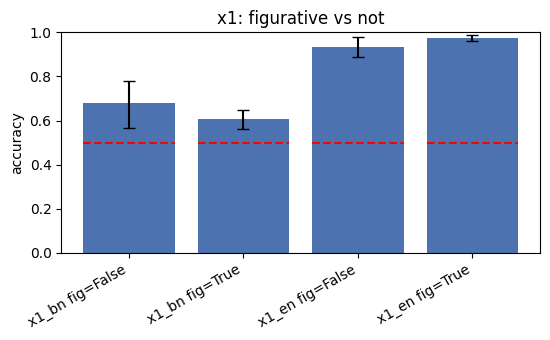

In [67]:

x1_fig = pd.concat([summary(g, by="figurative").assign(label=l) for l, g in RUNS["x1"].groupby("label")])
x1_fig.to_csv(OUT / "x1_figurative.csv", index=False); print(x1_fig.round(3).to_string())
bar(x1_fig.assign(cond=x1_fig["label"] + " fig=" + x1_fig["figurative"].astype(str)),
    "x1: figurative vs not", "x1_figurative.png", x="cond")


In [68]:
neg_rows = []
for pos_l, neg_l in NEG_PAIRS:
    if not have(pos_l, neg_l):
        continue
    m = item_level(sub(pos_l), ()).merge(item_level(sub(neg_l), ()), on="item_id", suffixes=("_pos", "_neg"))
    picked_correct_pos = m["correct_pos"] >= 0.5          # x1 gold = correct meaning
    picked_correct_neg = m["correct_neg"] < 0.5           # x2 gold = literal, so a miss = picked correct
    neg_rows.append({"pos": pos_l, "neg": neg_l, "acc_pos": m["correct_pos"].mean(), "acc_neg": m["correct_neg"].mean(),
                     "sum": m["correct_pos"].mean() + m["correct_neg"].mean(),       # ~1.0 = ignores NOT
                     "same_option_both": (picked_correct_pos == picked_correct_neg).mean(),
                     "both_right": ((m["correct_pos"] >= 0.5) & (m["correct_neg"] >= 0.5)).mean(), "n": len(m)})
neg_tab = pd.DataFrame(neg_rows); neg_tab.to_csv(OUT / "x2_negation.csv", index=False); print(neg_tab.round(3).to_string())

     pos    neg  acc_pos  acc_neg    sum  same_option_both  both_right    n
0  x1_en  x2_en    0.968    0.483  1.452             0.515       0.468  600
1  x1_bn  x2_bn    0.617    0.408  1.025             0.962       0.032  600


x3 pick rates (chance 1/3 each)
 pred_key  literal   none  plausible
label                              
x3_bn       0.207  0.567      0.227
x3_en       0.203  0.048      0.748


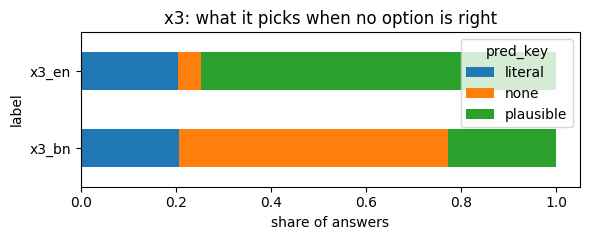

In [69]:

x3 = picked_key(RUNS["x3"].assign(gold=lambda d: d["gold"].str.lower(), pred=lambda d: d["pred"].str.lower()),
                ("literal", "plausible", "none"), none_last=True)
x3_tab = x3.groupby("label")["pred_key"].value_counts(normalize=True).unstack().fillna(0)
x3_tab.to_csv(OUT / "x3_picks.csv"); print("x3 pick rates (chance 1/3 each)\n", x3_tab.round(3))
x3_tab.plot.barh(stacked=True, figsize=(6, 0.5 * len(x3_tab) + 1.5), title="x3: what it picks when no option is right")
plt.xlabel("share of answers"); plt.tight_layout(); plt.savefig(FIG / "x3_picks.png", dpi=150); plt.show()


x4_en -> x1_en 
 uses          doesn't use  uses
knows                          
doesn't know            6    63
knows                  13   518
x4_bn -> x1_bn 
 uses          doesn't use  uses
knows                          
doesn't know          204    80
knows                  26   290


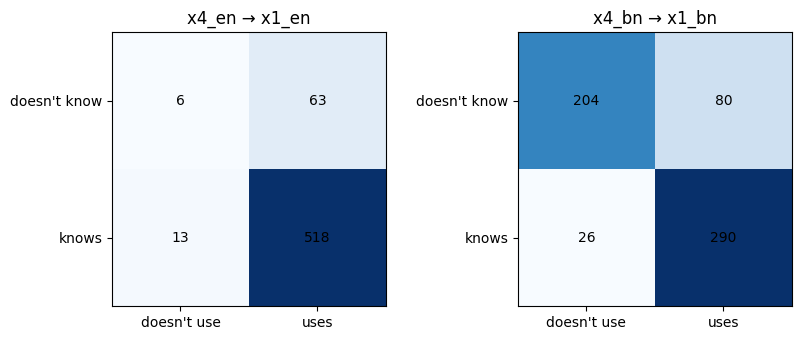

    know    use  knows_meaning  acc_in_context  ci_lo  ci_hi    n
0  x4_en  x1_en          False           0.913  0.840  0.983   69
1  x4_en  x1_en           True           0.976  0.961  0.989  531
2  x4_bn  x1_bn          False           0.282  0.224  0.340  284
3  x4_bn  x1_bn           True           0.918  0.878  0.957  316


In [70]:

know_rows, pairs_ok = [], [p for p in KNOW_PAIRS if have(*p)]
if pairs_ok:
    fig, axes = plt.subplots(1, len(pairs_ok), figsize=(4.2 * len(pairs_ok), 3.5), squeeze=False)
for ax, (k_l, u_l) in zip(axes[0] if pairs_ok else [], pairs_ok):
    m = item_level(sub(u_l), ()).merge(item_level(sub(k_l), ())[["item_id", "correct"]],
                                       on="item_id", suffixes=("", "_know"))
    m["knows"], m["uses"] = m["correct_know"] >= 0.5, m["correct"] >= 0.5
    for kn, g in m.groupby("knows"):
        lo, hi = ci(g["correct"], g["proverb_id"])
        know_rows.append({"know": k_l, "use": u_l, "knows_meaning": kn, "acc_in_context": g["correct"].mean(),
                          "ci_lo": lo, "ci_hi": hi, "n": len(g)})
    quad = pd.crosstab(m["knows"].map({True: "knows", False: "doesn't know"}),
                       m["uses"].map({True: "uses", False: "doesn't use"}))
    print(k_l, "->", u_l, "\n", quad); heat(ax, quad, f"{k_l} → {u_l}")
if pairs_ok:
    plt.tight_layout(); fig.savefig(FIG / "x4_knowing_vs_using.png", dpi=150); plt.show()
know_tab = pd.DataFrame(know_rows); know_tab.to_csv(OUT / "x4_knowing_vs_using.csv", index=False)
print(know_tab.round(3).to_string())


x5 pick rates (chance 1/3 each)
 pred_key  correct  literal  plausible  literal_share_of_errors
label                                                         
x5_bn       0.577    0.192      0.232                    0.453
x5_en       0.840    0.020      0.140                    0.125


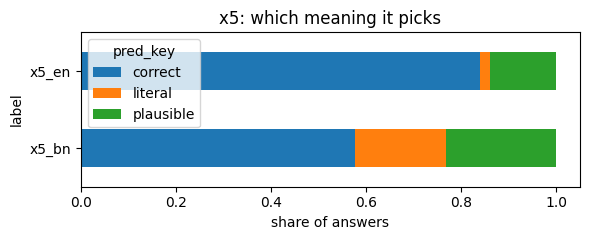

In [71]:
x5 = picked_key(RUNS["x5"].assign(gold=lambda d: d["gold"].str.lower(), pred=lambda d: d["pred"].str.lower()),
                ("correct", "literal", "plausible"))
ok = (x5["gold_key"] == "correct").mean()
if ok < 1:
    print(f"WARNING x5: option order re-created for only {ok:.0%} of rows; add a 'seed' column per run")
x5_tab = x5.groupby("label")["pred_key"].value_counts(normalize=True).unstack().fillna(0)
x5_tab["literal_share_of_errors"] = x5_tab["literal"] / (x5_tab["literal"] + x5_tab["plausible"])
x5_tab.to_csv(OUT / "x5_picks.csv"); print("x5 pick rates (chance 1/3 each)\n", x5_tab.round(3))
x5_tab[["correct", "literal", "plausible"]].plot.barh(stacked=True, figsize=(6, 0.5 * len(x5_tab) + 1.5),
                                                      title="x5: which meaning it picks")
plt.xlabel("share of answers"); plt.tight_layout(); plt.savefig(FIG / "x5_picks.png", dpi=150); plt.show()

              a              b  acc_a  acc_b   diff  ci_lo  ci_hi  a_only  b_only    n
0  x6_romanised     x6_bengali  0.968  0.895 -0.073 -0.098 -0.050      48       4  600
1  x6_romanised       x6_gloss  0.968  0.830 -0.138 -0.172 -0.103      88       5  600
2  x6_romanised  x6_gloss_only  0.968  0.780 -0.188 -0.225 -0.150     120       7  600


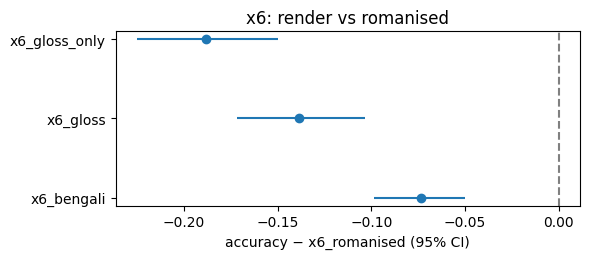

In [72]:

if have(X6_REF):
    x6_tab = pd.DataFrame([paired(sub(X6_REF), g, X6_REF, l) for l, g in RUNS["x6"].groupby("label") if l != X6_REF])
    x6_tab.to_csv(OUT / "x6_render_vs_ref.csv", index=False); print(x6_tab.round(3).to_string())
    forest(x6_tab, "x6: render vs romanised", "x6_render.png")


In [73]:
ctrl = pd.DataFrame([paired(sub(a), sub(b), a, b) for a, b in CONTROL_PAIRS if have(a, b)])
ctrl.to_csv(OUT / "x7_no_question.csv", index=False); print(ctrl.round(3).to_string())   # diff ~0 = question not used

       a      b  acc_a  acc_b   diff  ci_lo  ci_hi  a_only  b_only    n
0  x1_en  x7_en  0.968  0.975  0.007 -0.007  0.020       7      11  600
1  x1_bn  x7_bn  0.617  0.703  0.087  0.062  0.113       6      58  600


In [106]:
if have(X8_REF):
    x8_tab = pd.DataFrame([paired(sub(X8_REF), g, X8_REF, l) for l, g in RUNS["x8"].groupby("label") if l != X8_REF])
    x8_tab.to_csv(OUT / "x8_system_vs_C0.csv", index=False); print(x8_tab.round(3).to_string())
    forest(x8_tab, "x8: system prompt vs C0", "x8_system.png")

skip, label missing: ('x8_C0',)


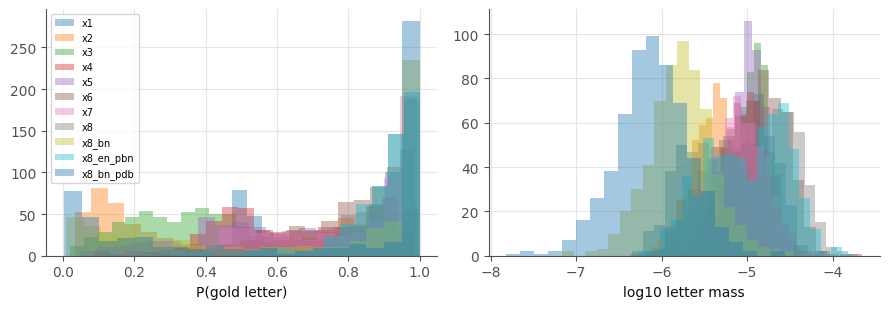

In [105]:

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for name, df in RUNS.items():
    it = item_level(df, ())
    axes[0].hist(it["p_gold"], bins=20, alpha=0.4, label=name)
    axes[1].hist(np.log10(it["letter_mass"]), bins=20, alpha=0.4, label=name)
axes[0].set_xlabel("P(gold letter)"); axes[1].set_xlabel("log10 letter mass"); axes[0].legend(fontsize=7)
plt.tight_layout(); fig.savefig(FIG / "x_confidence.png", dpi=150); plt.show()

In [83]:
PROMPT_RUNS = {"en": RUNS["x8"], "bn": RUNS["x8_bn"]}
ORDER = ["C0", "C1a", "C1b", "C1c"]                    # C1c = GEPA prompt (label x8_en_C1c / x8_bn_C1c)
LANG_COLOR = {"en": "#2a78d6", "bn": "#eb6834"}
GAIN, LOSS, MID = "#2a78d6", "#e34948", "#f0efec"      # fixed / broken / neutral
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})

def prompt_items(df):
    it = item_level(df)
    it["cond"] = it["label"].str.split("_").str[-1]
    return it[it["cond"].isin(ORDER)]

P = {lang: prompt_items(df) for lang, df in PROMPT_RUNS.items()}
conds = [c for c in ORDER if any((P[l]["cond"] == c).any() for l in P)]
right = {l: (it.pivot_table(index=["item_id", "proverb_id"], columns="cond", values="correct") >= 0.5)[
             [c for c in conds if c in set(it["cond"])]] for l, it in P.items()}
pgold = {l: it.pivot_table(index="item_id", columns="cond", values="p_gold")[right[l].columns] for l, it in P.items()}



In [86]:
rows = []
for l, it in P.items():
    R = right[l]
    for c in R.columns:
        g = it[it["cond"] == c]
        lo, hi = ci(g["correct"], g["proverb_id"])
        raw = sub(g["label"].iloc[0])
        rows.append({"lang": l, "cond": c, "acc": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi,
                     "acc_db": g["correct_db"].mean(), "pred_a": (raw["pred"] == "a").mean(),
                     "pred_b": (raw["pred"] == "b").mean(),
                     "fixed_vs_C0": int((R[c] & ~R["C0"]).sum()), "broken_vs_C0": int((~R[c] & R["C0"]).sum()),
                     "only_this_prompt": int((R[c] & ~R.drop(columns=c).any(axis=1)).sum()), "n": len(g)})
    any_right = R.any(axis=1).astype(float)
    lo, hi = ci(any_right, R.index.get_level_values("proverb_id"))
    rows.append({"lang": l, "cond": "any prompt", "acc": any_right.mean(), "ci_lo": lo, "ci_hi": hi, "n": len(R)})
prompt_tab = pd.DataFrame(rows)
prompt_tab["net_vs_C0"] = prompt_tab["fixed_vs_C0"] - prompt_tab["broken_vs_C0"]
prompt_tab.to_csv(OUT / "x8_prompts.csv", index=False); display(prompt_tab.round(3))


,lang,cond,acc,ci_lo,ci_hi,acc_db,pred_a,pred_b,fixed_vs_C0,broken_vs_C0,only_this_prompt,n,net_vs_C0
0,en,C0,0.968,0.952,0.982,NaN,0.498,0.502,0.0,0.0,2.0,600,0.0
1,en,C1a,0.967,0.950,0.982,NaN,0.500,0.500,2.0,3.0,0.0,600,-1.0
2,en,C1b,0.970,0.955,0.983,NaN,0.493,0.507,7.0,6.0,5.0,600,1.0
3,en,any prompt,0.980,0.965,0.992,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN
4,bn,C0,0.617,0.577,0.657,NaN,0.107,0.893,0.0,0.0,0.0,600,0.0
5,bn,C1a,0.648,0.607,0.688,NaN,0.138,0.862,20.0,1.0,1.0,600,19.0
6,bn,C1b,0.722,0.678,0.762,NaN,0.228,0.772,68.0,5.0,49.0,600,63.0
7,bn,any prompt,0.732,0.688,0.772,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN


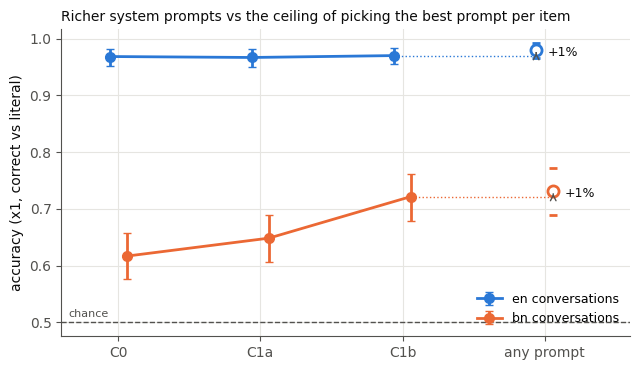

In [87]:

fig, ax = plt.subplots(figsize=(6.5, 3.8))
xs = {c: i for i, c in enumerate(conds + ["any prompt"])}
for j, l in enumerate(P):
    t = prompt_tab[prompt_tab["lang"] == l].set_index("cond")
    real = [c for c in conds if c in t.index]
    off = (j - 0.5) * 0.12
    ax.errorbar([xs[c] + off for c in real], t.loc[real, "acc"],
                yerr=[t.loc[real, "acc"] - t.loc[real, "ci_lo"], t.loc[real, "ci_hi"] - t.loc[real, "acc"]],
                color=LANG_COLOR[l], lw=2, marker="o", ms=7, capsize=3, label=f"{l} conversations")
    ceil, best = t.loc["any prompt"], t.loc[real, "acc"].max()
    ax.errorbar(xs["any prompt"] + off, ceil["acc"], yerr=[[ceil["acc"] - ceil["ci_lo"]], [ceil["ci_hi"] - ceil["acc"]]],
                color=LANG_COLOR[l], marker="o", ms=8, mfc="white", mew=2, capsize=3, lw=0)
    ax.hlines(best, xs[t.loc[real, "acc"].idxmax()] + off, xs["any prompt"] + off, colors=LANG_COLOR[l], ls=":", lw=1)
    ax.annotate("", xy=(xs["any prompt"] + off, ceil["acc"]), xytext=(xs["any prompt"] + off, best),
                arrowprops=dict(arrowstyle="->", color=MUTED, lw=1))
    ax.text(xs["any prompt"] + off + 0.08, (best + ceil["acc"]) / 2, f"+{ceil['acc'] - best:.0%}", color=INK, va="center", fontsize=9)
ax.axhline(0.5, color=MUTED, ls="--", lw=1); ax.text(-0.35, 0.505, "chance", color=MUTED, fontsize=8, va="bottom")
ax.set_xticks(list(xs.values()), list(xs.keys())); ax.set_xlim(-0.4, len(xs) - 0.4)
ax.set_ylabel("accuracy (x1, correct vs literal)")
ax.set_title("Richer system prompts vs the ceiling of picking the best prompt per item", color=INK, fontsize=10, loc="left")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout(); fig.savefig(FIG / "x8_ladder.png", dpi=150); plt.show()



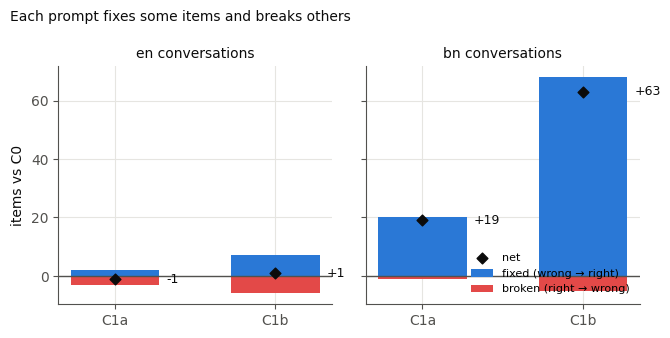

In [88]:
cmp = [c for c in conds if c != "C0"]
fig, axes = plt.subplots(1, len(P), figsize=(3.4 * len(P), 3.4), sharey=True, squeeze=False)
for ax, l in zip(axes[0], P):
    t = prompt_tab[(prompt_tab["lang"] == l) & prompt_tab["cond"].isin(cmp)].set_index("cond").reindex(cmp)
    x = np.arange(len(cmp))
    ax.bar(x, t["fixed_vs_C0"], width=0.55, color=GAIN, label="fixed (wrong → right)")
    ax.bar(x, -t["broken_vs_C0"], width=0.55, color=LOSS, label="broken (right → wrong)")
    ax.scatter(x, t["net_vs_C0"], color=INK, marker="D", s=30, zorder=3, label="net")
    for xi, v in zip(x, t["net_vs_C0"]):
        ax.text(xi + 0.32, v, f"{v:+.0f}", color=INK, va="center", fontsize=9)
    ax.axhline(0, color=MUTED, lw=1); ax.set_xticks(x, cmp); ax.set_title(f"{l} conversations", color=INK, fontsize=10)
axes[0, 0].set_ylabel("items vs C0")
axes[0, -1].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Each prompt fixes some items and breaks others", color=INK, fontsize=10, x=0.02, ha="left")
plt.tight_layout(); fig.savefig(FIG / "x8_fixed_broken.png", dpi=150); plt.show()



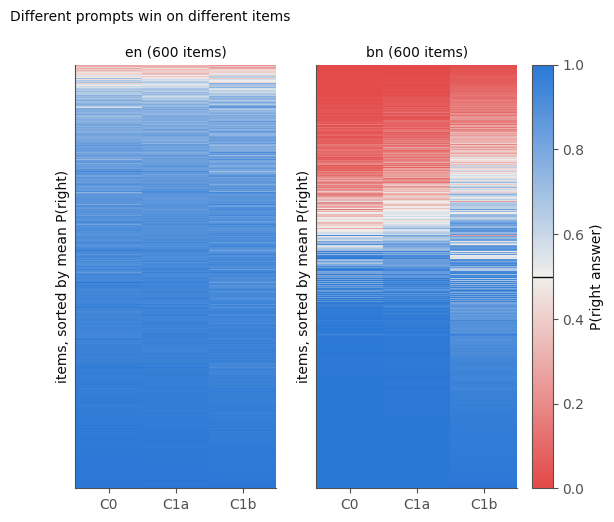

In [89]:
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", [LOSS, MID, GAIN])
fig, axes = plt.subplots(1, len(P), figsize=(2.6 * len(P) + 1, 5.5), squeeze=False)
for ax, l in zip(axes[0], P):
    M = pgold[l]
    M = M.loc[M.mean(axis=1).sort_values().index]
    im = ax.imshow(M.values, aspect="auto", cmap=div, vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks(range(M.shape[1]), M.columns); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"{l} ({len(M)} items)", color=INK, fontsize=10); ax.set_ylabel("items, sorted by mean P(right)")
cb = fig.colorbar(im, ax=axes[0].tolist(), fraction=0.05, pad=0.03); cb.set_label("P(right answer)")
cb.ax.axhline(0.5, color=INK, lw=1)
fig.suptitle("Different prompts win on different items", color=INK, fontsize=10, x=0.02, ha="left")
fig.savefig(FIG / "x8_item_map.png", dpi=150, bbox_inches="tight"); plt.show()



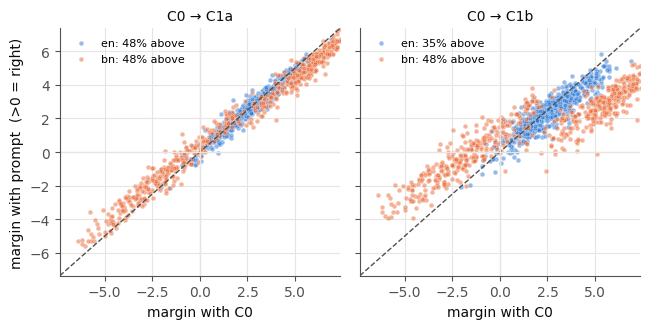

In [91]:
mg = {l: it.pivot_table(index="item_id", columns="cond", values="margin") for l, it in P.items()}
fig, axes = plt.subplots(1, len(cmp), figsize=(3.3 * len(cmp), 3.4), sharex=True, sharey=True, squeeze=False)
lim = np.nanpercentile(np.abs(pd.concat(mg.values()).values), 99)
for ax, c in zip(axes[0], cmp):
    for l in P:
        if c in mg[l]:
            ax.scatter(mg[l]["C0"], mg[l][c], s=12, alpha=0.5, color=LANG_COLOR[l], edgecolors="white", linewidths=0.4,
                       label=f"{l}: {(mg[l][c] > mg[l]['C0']).mean():.0%} above")
    ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=1, ls="--")
    ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_title(f"C0 → {c}", color=INK, fontsize=10)
    ax.set_xlabel("margin with C0"); ax.legend(frameon=False, fontsize=8, loc="upper left")
axes[0, 0].set_ylabel("margin with prompt  (>0 = right)")
plt.tight_layout(); fig.savefig(FIG / "x8_margin_shift.png", dpi=150); plt.show()

                   run        cond    acc  ci_lo  ci_hi  acc_db  pred_a  pred_b  fixed_vs_C0  broken_vs_C0  only_this_prompt    n  net_vs_C0
0  en prompt · en conv          C0  0.968  0.952  0.982     NaN   0.498   0.502          0.0           0.0               2.0  600        0.0
1  en prompt · en conv         C1a  0.967  0.950  0.982     NaN   0.500   0.500          2.0           3.0               0.0  600       -1.0
2  en prompt · en conv         C1b  0.970  0.955  0.983     NaN   0.493   0.507          7.0           6.0               5.0  600        1.0
3  en prompt · en conv  any prompt  0.980  0.965  0.992     NaN     NaN     NaN          NaN           NaN               NaN  600        NaN
4  en prompt · bn conv          C0  0.617  0.577  0.657     NaN   0.107   0.893          0.0           0.0               0.0  600        0.0
5  en prompt · bn conv         C1a  0.648  0.607  0.688     NaN   0.138   0.862         20.0           1.0               1.0  600       19.0
6  en prompt 

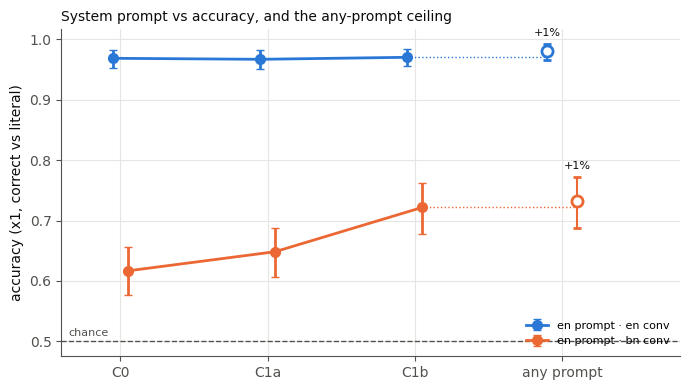

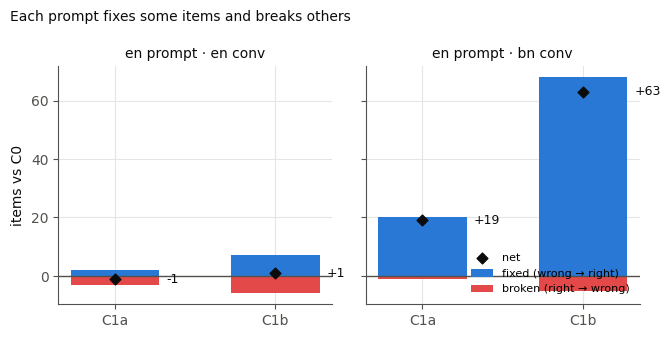

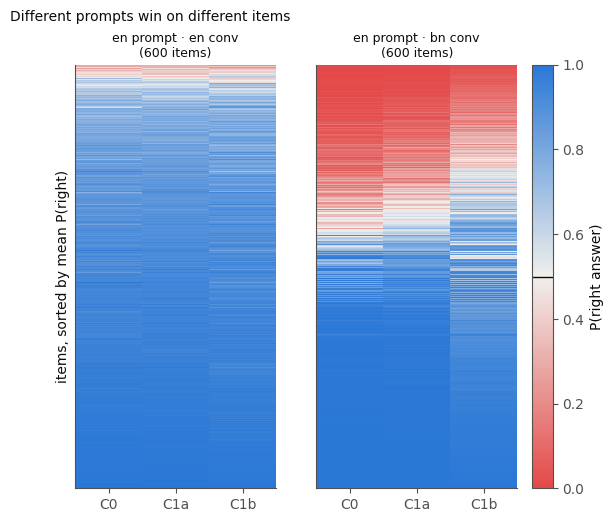

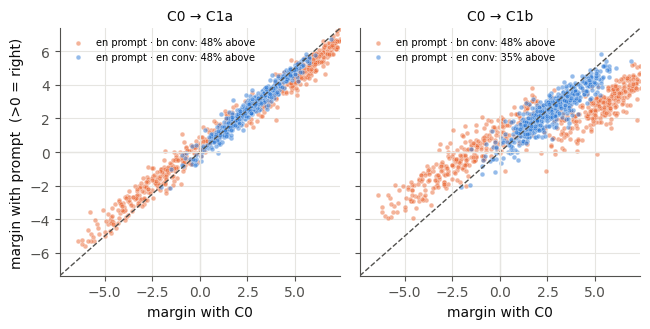

                   run        cond    acc  ci_lo  ci_hi  acc_db  pred_a  pred_b  fixed_vs_C0  broken_vs_C0  only_this_prompt    n  net_vs_C0
0  bn prompt · en conv          C0  0.968  0.952  0.982     NaN   0.498   0.502          0.0           0.0               0.0  600        0.0
1  bn prompt · en conv         C1a  0.968  0.952  0.982     NaN   0.495   0.505          4.0           4.0               0.0  600        0.0
2  bn prompt · en conv         C1b  0.978  0.965  0.990     NaN   0.485   0.515          9.0           3.0               5.0  600        6.0
3  bn prompt · en conv  any prompt  0.983  0.970  0.993     NaN     NaN     NaN          NaN           NaN               NaN  600        NaN
4  bn prompt · bn conv          C0  0.617  0.577  0.657     NaN   0.107   0.893          0.0           0.0               8.0  600        0.0
5  bn prompt · bn conv         C1a  0.623  0.583  0.665     NaN   0.113   0.887         12.0           8.0               7.0  600        4.0
6  bn prompt 

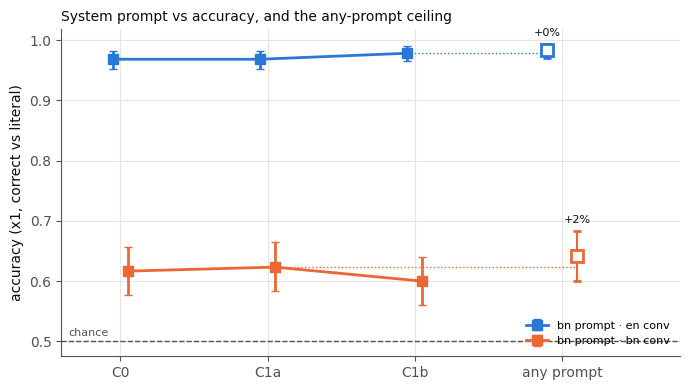

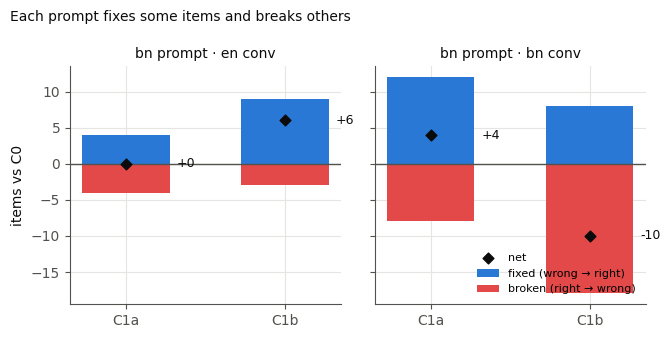

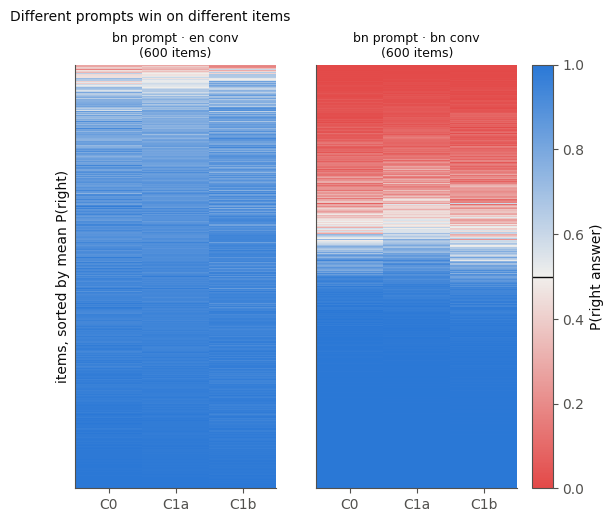

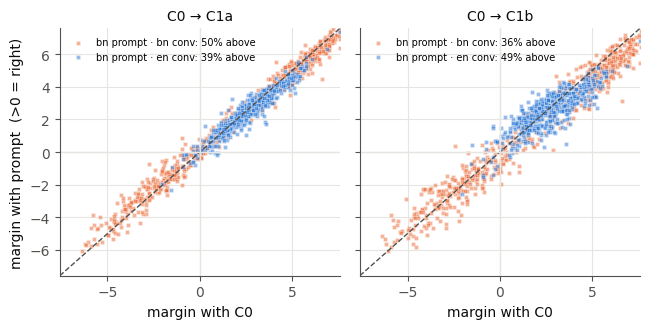

                    run        cond    acc  ci_lo  ci_hi  acc_db  pred_a  pred_b  fixed_vs_C0  broken_vs_C0  only_this_prompt    n  net_vs_C0
0   en prompt · en conv          C0  0.968  0.952  0.982     NaN   0.498   0.502          0.0           0.0               2.0  600        0.0
1   en prompt · en conv         C1a  0.967  0.950  0.982     NaN   0.500   0.500          2.0           3.0               0.0  600       -1.0
2   en prompt · en conv         C1b  0.970  0.955  0.983     NaN   0.493   0.507          7.0           6.0               5.0  600        1.0
3   en prompt · en conv  any prompt  0.980  0.965  0.992     NaN     NaN     NaN          NaN           NaN               NaN  600        NaN
4   en prompt · bn conv          C0  0.617  0.577  0.657     NaN   0.107   0.893          0.0           0.0               0.0  600        0.0
5   en prompt · bn conv         C1a  0.648  0.607  0.688     NaN   0.138   0.862         20.0           1.0               1.0  600       19.0
6   en

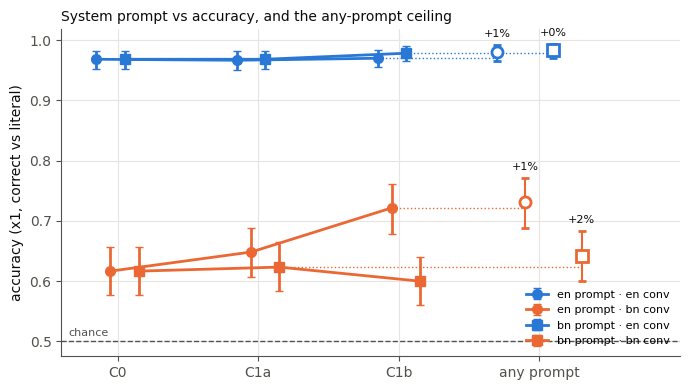

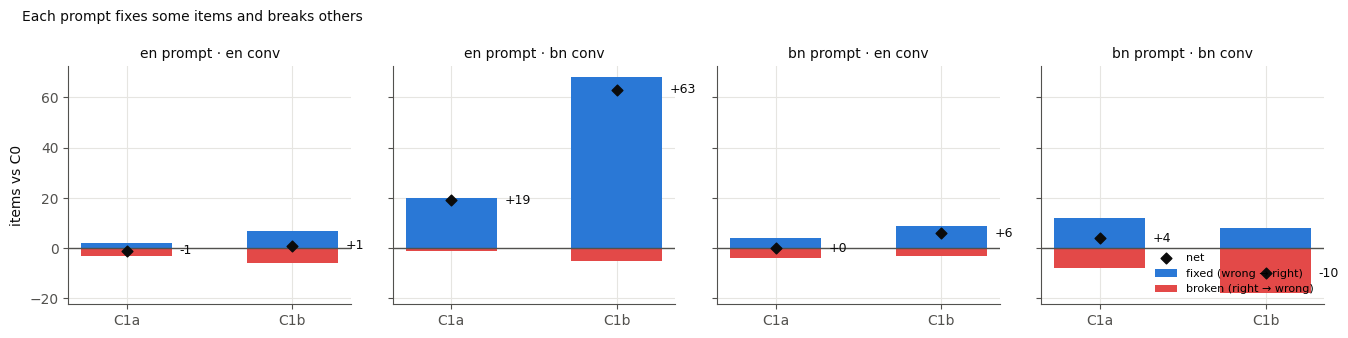

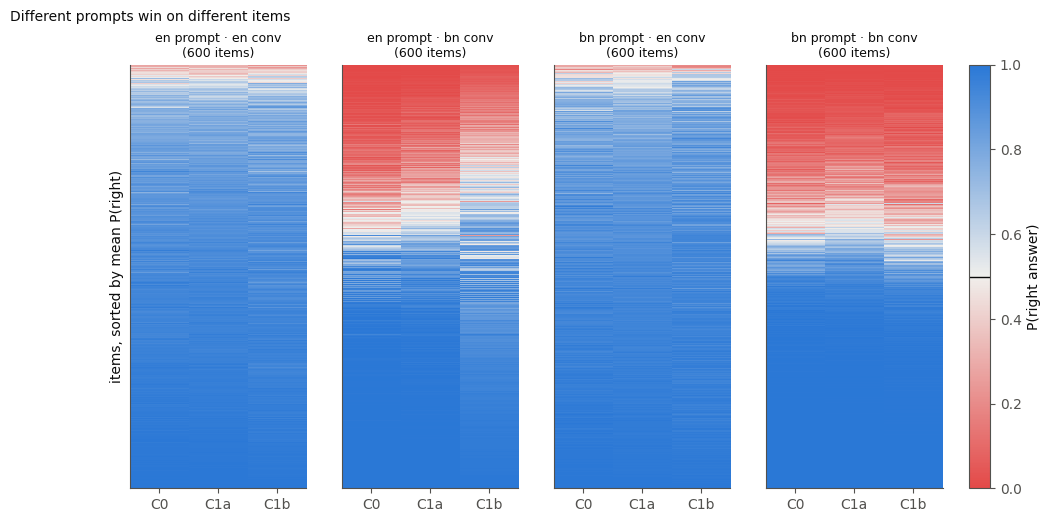

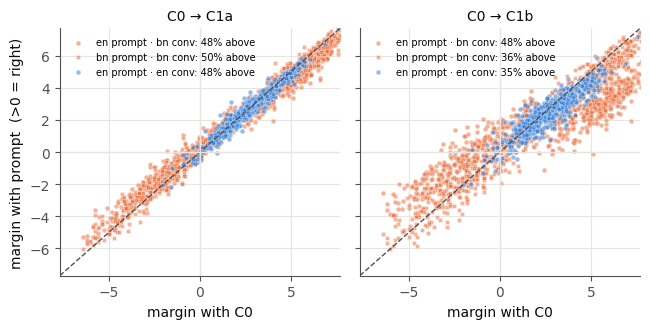

conv            bn     en
cond prompt              
C0   bn      0.617  0.968
     en      0.617  0.968
C1a  bn      0.623  0.968
     en      0.648  0.967
C1b  bn      0.600  0.978
     en      0.722  0.970


In [107]:
RUNS = {"x1": x1_results_df, "x2": x2_results_df, "x3": x3_results_df, "x4": x4_results_df,
        "x5": x5_results_df, "x6": x6_results_df, "x7": x7_results_df, "x8": x8_results_df,
        "x8_bn": x8_bn_results_df, "x8_en_pbn": x8_en_pbn_results_df, "x8_bn_pdb": x8_bn_pbn_results_df}

# ================================================================ 9. system prompts: English vs Bengali prompts
from matplotlib.colors import LinearSegmentedColormap

ORDER = ["C0", "C1a", "C1b", "C1c"]                    # C1c = GEPA prompt
C0_FROM = {"en conv": x8_results_df, "bn conv": x8_bn_results_df}   # C0 = no system prompt, shared by both prompt languages
GAIN, LOSS, MID = "#2a78d6", "#e34948", "#f0efec"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})

def prompt_items(df):
    it = item_level(df)
    it["cond"] = it["label"].str.split("_").str[-1]
    return it[it["cond"].isin(ORDER)]

def prompt_plots(runs, tag):
    """runs = {"<en|bn> prompt · <en|bn> conv": df}. Colour = conversation language, marker = prompt language."""
    color = {k: "#2a78d6" if k.endswith("en conv") else "#eb6834" for k in runs}
    mark = {k: "s" if k.startswith("bn prompt") else "o" for k in runs}
    P = {}
    for k, df in runs.items():
        it = prompt_items(df)
        if not (it["cond"] == "C0").any():                     # borrow C0 from the same conversation language
            c0 = prompt_items(C0_FROM[k.split("· ")[-1]])
            it = pd.concat([c0[c0["cond"] == "C0"], it], ignore_index=True)
        P[k] = it
    conds = [c for c in ORDER if any((P[k]["cond"] == c).any() for k in P)]
    right = {k: (it.pivot_table(index=["item_id", "proverb_id"], columns="cond", values="correct") >= 0.5)[
                 [c for c in conds if c in set(it["cond"])]] for k, it in P.items()}
    pgold = {k: it.pivot_table(index="item_id", columns="cond", values="p_gold")[right[k].columns] for k, it in P.items()}

    # ---- table
    rows = []
    for k, it in P.items():
        R = right[k]
        for c in R.columns:
            g = it[it["cond"] == c]
            lo, hi = ci(g["correct"], g["proverb_id"])
            raw = sub(g["label"].iloc[0])
            rows.append({"run": k, "cond": c, "acc": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi,
                         "acc_db": g["correct_db"].mean(), "pred_a": (raw["pred"] == "a").mean(),
                         "pred_b": (raw["pred"] == "b").mean(),
                         "fixed_vs_C0": int((R[c] & ~R["C0"]).sum()), "broken_vs_C0": int((~R[c] & R["C0"]).sum()),
                         "only_this_prompt": int((R[c] & ~R.drop(columns=c).any(axis=1)).sum()), "n": len(g)})
        any_right = R.any(axis=1).astype(float)
        lo, hi = ci(any_right, R.index.get_level_values("proverb_id"))
        rows.append({"run": k, "cond": "any prompt", "acc": any_right.mean(), "ci_lo": lo, "ci_hi": hi, "n": len(R)})
    tab = pd.DataFrame(rows)
    tab["net_vs_C0"] = tab["fixed_vs_C0"] - tab["broken_vs_C0"]
    tab.to_csv(OUT / f"x8_{tag}_prompts.csv", index=False); print(tab.round(3).to_string())

    # ---- 9a. ladder + any-prompt ceiling
    fig, ax = plt.subplots(figsize=(7, 4))
    xs = {c: i for i, c in enumerate(conds + ["any prompt"])}
    for j, k in enumerate(P):
        t = tab[tab["run"] == k].set_index("cond")
        real = [c for c in conds if c in t.index]
        off = (j - (len(P) - 1) / 2) * 0.1
        ax.errorbar([xs[c] + off for c in real], t.loc[real, "acc"],
                    yerr=[t.loc[real, "acc"] - t.loc[real, "ci_lo"], t.loc[real, "ci_hi"] - t.loc[real, "acc"]],
                    color=color[k], lw=2, marker=mark[k], ms=7, capsize=3, label=k)
        ceil, best = t.loc["any prompt"], t.loc[real, "acc"].max()
        xc = xs["any prompt"] + (j - (len(P) - 1) / 2) * 0.2           # spread the ceiling markers wider
        ax.errorbar(xc, ceil["acc"], yerr=[[ceil["acc"] - ceil["ci_lo"]], [ceil["ci_hi"] - ceil["acc"]]],
                    color=color[k], marker=mark[k], ms=8, mfc="white", mew=2, capsize=3, ls="none", elinewidth=1.5)
        ax.hlines(best, xs[t.loc[real, "acc"].idxmax()] + off, xc, colors=color[k], ls=":", lw=1)
        ax.text(xc, ceil["ci_hi"] + 0.01, f"+{ceil['acc'] - best:.0%}", color=INK, ha="center", va="bottom", fontsize=8)
    ax.axhline(0.5, color=MUTED, ls="--", lw=1); ax.text(-0.35, 0.505, "chance", color=MUTED, fontsize=8, va="bottom")
    ax.set_xticks(list(xs.values()), list(xs.keys())); ax.set_xlim(-0.4, len(xs) - 0.4 + 0.1 * len(P))
    ax.set_ylabel("accuracy (x1, correct vs literal)")
    ax.set_title("System prompt vs accuracy, and the any-prompt ceiling", color=INK, fontsize=10, loc="left")
    ax.legend(frameon=False, loc="lower right", fontsize=8)
    plt.tight_layout(); fig.savefig(FIG / f"x8_{tag}_ladder.png", dpi=150); plt.show()

    # ---- 9b. fixed / broken vs C0
    cmp = [c for c in conds if c != "C0"]
    fig, axes = plt.subplots(1, len(P), figsize=(3.4 * len(P), 3.4), sharey=True, squeeze=False)
    for ax, k in zip(axes[0], P):
        t = tab[(tab["run"] == k) & tab["cond"].isin(cmp)].set_index("cond").reindex(cmp)
        x = np.arange(len(cmp))
        ax.bar(x, t["fixed_vs_C0"], width=0.55, color=GAIN, label="fixed (wrong → right)")
        ax.bar(x, -t["broken_vs_C0"], width=0.55, color=LOSS, label="broken (right → wrong)")
        ax.scatter(x, t["net_vs_C0"], color=INK, marker="D", s=30, zorder=3, label="net")
        for xi, v in zip(x, t["net_vs_C0"]):
            ax.text(xi + 0.32, v, f"{v:+.0f}", color=INK, va="center", fontsize=9)
        ax.axhline(0, color=MUTED, lw=1); ax.set_xticks(x, cmp); ax.set_title(k, color=INK, fontsize=10)
    axes[0, 0].set_ylabel("items vs C0"); axes[0, -1].legend(frameon=False, fontsize=8, loc="lower right")
    fig.suptitle("Each prompt fixes some items and breaks others", color=INK, fontsize=10, x=0.02, ha="left")
    plt.tight_layout(); fig.savefig(FIG / f"x8_{tag}_fixed_broken.png", dpi=150); plt.show()

    # ---- 9c. item x prompt map
    div = LinearSegmentedColormap.from_list("div", [LOSS, MID, GAIN])
    fig, axes = plt.subplots(1, len(P), figsize=(2.6 * len(P) + 1, 5.5), squeeze=False)
    for ax, k in zip(axes[0], P):
        M = pgold[k].loc[pgold[k].mean(axis=1).sort_values().index]
        im = ax.imshow(M.values, aspect="auto", cmap=div, vmin=0, vmax=1, interpolation="nearest")
        ax.set_xticks(range(M.shape[1]), M.columns); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{k}\n({len(M)} items)", color=INK, fontsize=9)
    axes[0, 0].set_ylabel("items, sorted by mean P(right)")
    cb = fig.colorbar(im, ax=axes[0].tolist(), fraction=0.05, pad=0.03); cb.set_label("P(right answer)")
    cb.ax.axhline(0.5, color=INK, lw=1)
    fig.suptitle("Different prompts win on different items", color=INK, fontsize=10, x=0.02, ha="left")
    fig.savefig(FIG / f"x8_{tag}_item_map.png", dpi=150, bbox_inches="tight"); plt.show()

    # ---- 9d. margin shift (at most 3 runs per panel, Bengali conversations first)
    show = sorted(P, key=lambda k: not k.endswith("bn conv"))[:3]
    mg = {k: P[k].pivot_table(index="item_id", columns="cond", values="margin") for k in show}
    fig, axes = plt.subplots(1, len(cmp), figsize=(3.3 * len(cmp), 3.4), sharex=True, sharey=True, squeeze=False)
    lim = np.nanpercentile(np.abs(pd.concat(mg.values()).values), 99)
    for ax, c in zip(axes[0], cmp):
        for k in show:
            if c in mg[k]:
                ax.scatter(mg[k]["C0"], mg[k][c], s=12, alpha=0.5, color=color[k], marker=mark[k], edgecolors="white",
                           linewidths=0.4, label=f"{k}: {(mg[k][c] > mg[k]['C0']).mean():.0%} above")
        ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=1, ls="--")
        ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_title(f"C0 → {c}", color=INK, fontsize=10)
        ax.set_xlabel("margin with C0"); ax.legend(frameon=False, fontsize=7, loc="upper left")
    axes[0, 0].set_ylabel("margin with prompt  (>0 = right)")
    plt.tight_layout(); fig.savefig(FIG / f"x8_{tag}_margin_shift.png", dpi=150); plt.show()
    return tab

EN_P = {"en prompt · en conv": x8_results_df, "en prompt · bn conv": x8_bn_results_df}
BN_P = {"bn prompt · en conv": x8_en_pbn_results_df, "bn prompt · bn conv": x8_bn_pbn_results_df}
tab_en = prompt_plots(EN_P, "en_prompt")
tab_bn = prompt_plots(BN_P, "bn_prompt")
tab_all = prompt_plots({**EN_P, **BN_P}, "all")

# ---- 2x2 summary: prompt language x conversation language
t = tab_all[tab_all["cond"] != "any prompt"].copy()
t["prompt"], t["conv"] = t["run"].str.split().str[0], t["run"].str.split().str[-2]
print(t.pivot_table(index=["cond", "prompt"], columns="conv", values="acc").round(3))

In [108]:
!zip -r /kaggle/working/results_mine_alligned_bloomz.zip /kaggle/working/results_mine_alligned_bloomz

  adding: kaggle/working/results_mine_alligned_bloomz/ (stored 0%)
  adding: kaggle/working/results_mine_alligned_bloomz/x8_prompts.csv (deflated 67%)
  adding: kaggle/working/results_mine_alligned_bloomz/figs_x/ (stored 0%)
  adding: kaggle/working/results_mine_alligned_bloomz/figs_x/x8_en_prompt_margin_shift.png (deflated 2%)
  adding: kaggle/working/results_mine_alligned_bloomz/figs_x/x8_bn_prompt_ladder.png (deflated 11%)
  adding: kaggle/working/results_mine_alligned_bloomz/figs_x/x8_bn_prompt_margin_shift.png (deflated 3%)
  adding: kaggle/working/results_mine_alligned_bloomz/figs_x/x8_all_item_map.png (deflated 9%)
  adding: kaggle/working/results_mine_alligned_bloomz/figs_x/x8_all_margin_shift.png (deflated 2%)
  adding: kaggle/working/results_mine_alligned_bloomz/figs_x/x_confidence.png (deflated 12%)
  adding: kaggle/working/results_mine_alligned_bloomz/figs_x/x8_en_prompt_fixed_broken.png (deflated 14%)
  adding: kaggle/working/results_mine_alligned_bloomz/figs_x/x8_en_promp